# Dataset Accepted 

In [3]:
import pandas as pd

# Load LendingClub accepted dataset
df_lending_accepted = pd.read_csv("data/accepted.csv", low_memory=False)

In [4]:
# Only load the header, not the full dataset
df_lending_header = pd.read_csv("data/accepted.csv", nrows=0)

# Show number of columns
print("Number of features:", len(df_lending_header.columns))

# Show all feature names
print("\nAll columns/features:")
for i, col in enumerate(df_lending_header.columns, start=1):
    print(f"{i}. {col}")

Number of features: 151

All columns/features:
1. id
2. member_id
3. loan_amnt
4. funded_amnt
5. funded_amnt_inv
6. term
7. int_rate
8. installment
9. grade
10. sub_grade
11. emp_title
12. emp_length
13. home_ownership
14. annual_inc
15. verification_status
16. issue_d
17. loan_status
18. pymnt_plan
19. url
20. desc
21. purpose
22. title
23. zip_code
24. addr_state
25. dti
26. delinq_2yrs
27. earliest_cr_line
28. fico_range_low
29. fico_range_high
30. inq_last_6mths
31. mths_since_last_delinq
32. mths_since_last_record
33. open_acc
34. pub_rec
35. revol_bal
36. revol_util
37. total_acc
38. initial_list_status
39. out_prncp
40. out_prncp_inv
41. total_pymnt
42. total_pymnt_inv
43. total_rec_prncp
44. total_rec_int
45. total_rec_late_fee
46. recoveries
47. collection_recovery_fee
48. last_pymnt_d
49. last_pymnt_amnt
50. next_pymnt_d
51. last_credit_pull_d
52. last_fico_range_high
53. last_fico_range_low
54. collections_12_mths_ex_med
55. mths_since_last_major_derog
56. policy_code
57. ap

# Rejected dataset

In [ ]:
import pandas as pd

# Load LendingClub accepted dataset
df_lending_accepted = pd.read_csv("data/rejected.csv", low_memory=False)

In [26]:
# Only load the header, not the full dataset
df_lending_header = pd.read_csv("data/rejected.csv", nrows=0)

# Show number of columns
print("Number of features:", len(df_lending_header.columns))

# Show all feature names
print("\nAll columns/features:")
for i, col in enumerate(df_lending_header.columns, start=1):
    print(f"{i}. {col}")

Number of features: 9

All columns/features:
1. Amount Requested
2. Application Date
3. Loan Title
4. Risk_Score
5. Debt-To-Income Ratio
6. Zip Code
7. State
8. Employment Length
9. Policy Code


count    9.151111e+06
mean     6.281721e+02
std      8.993679e+01
min      0.000000e+00
25%      5.910000e+02
50%      6.370000e+02
75%      6.750000e+02
max      9.900000e+02
Name: Risk_Score, dtype: float64

Missing values: 18497630


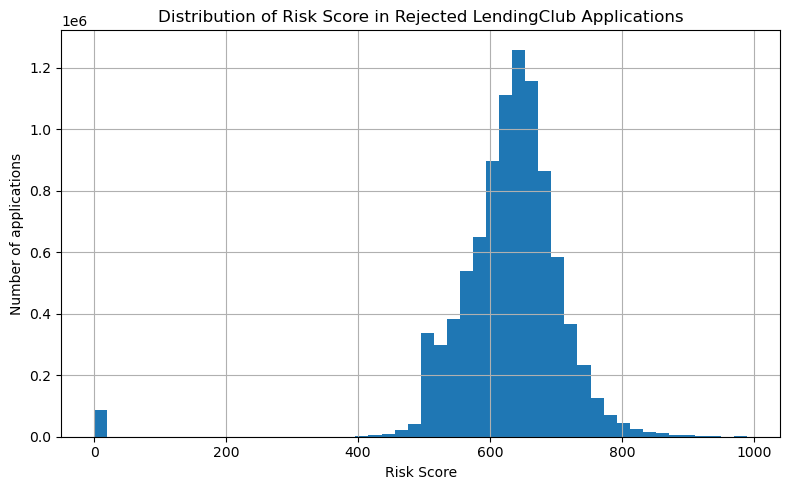

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

# Load rejected LendingClub applications
df_rejected = pd.read_csv("data/rejected.csv", low_memory=False)

# Basic info about Risk_Score
print(df_rejected["Risk_Score"].describe())
print("\nMissing values:", df_rejected["Risk_Score"].isna().sum())

# Plot distribution
plt.figure(figsize=(8, 5))
df_rejected["Risk_Score"].dropna().hist(bins=50)

plt.title("Distribution of Risk Score in Rejected LendingClub Applications")
plt.xlabel("Risk Score")
plt.ylabel("Number of applications")

plt.tight_layout()
plt.show()

# Visualisation Accepted dataset 

In [8]:
import matplotlib.pyplot as plt

# Load only relevant columns for quick exploration
lending_cols = [
    "loan_status",
    "loan_amnt",
    "annual_inc",
    "dti",
    "int_rate",
    "emp_length",
    "purpose",
    "grade",
    "home_ownership"
]

df_lending = pd.read_csv(
    "data/accepted.csv",
    usecols=lending_cols,
    low_memory=False
)

df_lending.head()

,loan_amnt,int_rate,grade,emp_length,home_ownership,annual_inc,loan_status,purpose,dti
0,3600.0,13.99,C,10+ years,MORTGAGE,55000.0,Fully Paid,debt_consolidation,5.91
1,24700.0,11.99,C,10+ years,MORTGAGE,65000.0,Fully Paid,small_business,16.06
2,20000.0,10.78,B,10+ years,MORTGAGE,63000.0,Fully Paid,home_improvement,10.78
3,35000.0,14.85,C,10+ years,MORTGAGE,110000.0,Current,debt_consolidation,17.06
4,10400.0,22.45,F,3 years,MORTGAGE,104433.0,Fully Paid,major_purchase,25.37


In [9]:
# Keep only final loan outcomes
df_lending_binary = df_lending[
    df_lending["loan_status"].isin(["Fully Paid", "Charged Off"])
].copy()

# Create binary target
# 0 = non-default / fully paid
# 1 = default / charged off
df_lending_binary["target"] = df_lending_binary["loan_status"].map({
    "Fully Paid": 0,
    "Charged Off": 1
})

print("Dataset shape after filtering:", df_lending_binary.shape)
df_lending_binary[["loan_status", "target"]].head()

Dataset shape after filtering: (1345310, 10)


,loan_status,target
0,Fully Paid,0
1,Fully Paid,0
2,Fully Paid,0
4,Fully Paid,0
5,Fully Paid,0


Class counts:
target
0    1076751
1     268559
Name: count, dtype: int64

Class percentages:
target
0    80.04
1    19.96
Name: proportion, dtype: float64


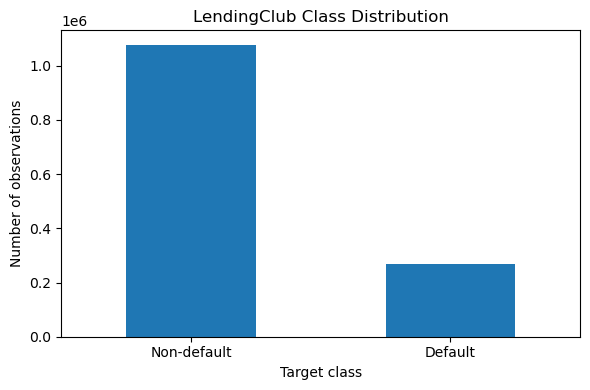

Imbalance ratio: 4.01:1


In [10]:
# Count target classes
target_counts = df_lending_binary["target"].value_counts().sort_index()
target_percentages = df_lending_binary["target"].value_counts(normalize=True).sort_index() * 100

print("Class counts:")
print(target_counts)

print("\nClass percentages:")
print(target_percentages.round(2))

# Plot class imbalance
plt.figure(figsize=(6, 4))
target_counts.plot(kind="bar")

plt.title("LendingClub Class Distribution")
plt.xlabel("Target class")
plt.ylabel("Number of observations")
plt.xticks(
    ticks=[0, 1],
    labels=["Non-default", "Default"],
    rotation=0
)

plt.tight_layout()
plt.show()

# Imbalance ratio
imbalance_ratio = target_counts.max() / target_counts.min()
print(f"Imbalance ratio: {imbalance_ratio:.2f}:1")

In [11]:
imbalance_table = pd.DataFrame({
    "Class": ["Non-default / Fully Paid", "Default / Charged Off"],
    "Target value": [0, 1],
    "Count": target_counts.values,
    "Percentage (%)": target_percentages.round(2).values
})

imbalance_table

,Class,Target value,Count,Percentage (%)
0,Non-default / Fully Paid,0,1076751,80.04
1,Default / Charged Off,1,268559,19.96


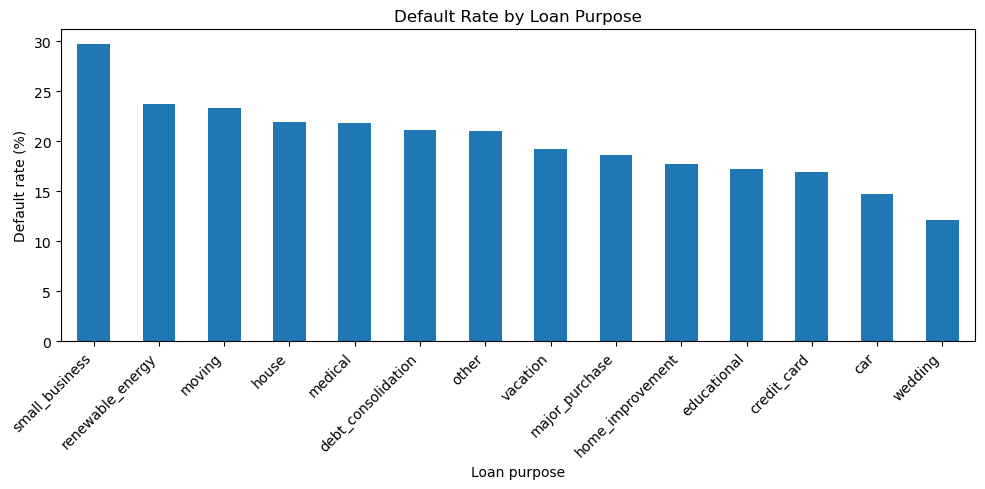

In [13]:
purpose_default_rate = (
    df_lending_binary
    .groupby("purpose")["target"]
    .mean()
    .sort_values(ascending=False) * 100
)

plt.figure(figsize=(10, 5))
purpose_default_rate.plot(kind="bar")

plt.title("Default Rate by Loan Purpose")
plt.xlabel("Loan purpose")
plt.ylabel("Default rate (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

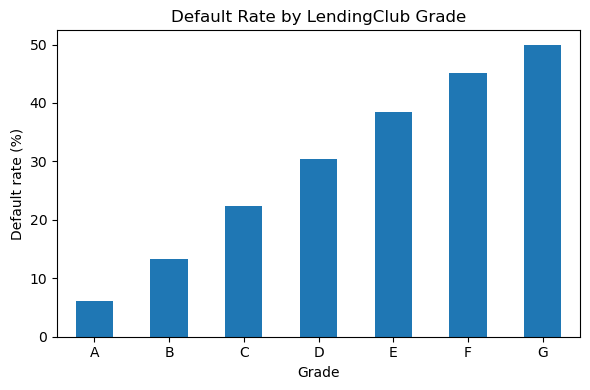

In [14]:
grade_default_rate = (
    df_lending_binary
    .groupby("grade")["target"]
    .mean()
    .sort_index() * 100
)

plt.figure(figsize=(6, 4))
grade_default_rate.plot(kind="bar")

plt.title("Default Rate by LendingClub Grade")
plt.xlabel("Grade")
plt.ylabel("Default rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [15]:
feature_attack_relevance = pd.DataFrame({
    "Feature": [
        "loan_amnt",
        "annual_inc",
        "dti",
        "int_rate",
        "emp_length",
        "purpose",
        "grade",
        "home_ownership"
    ],
    "Interpretation": [
        "Requested loan amount",
        "Borrower annual income",
        "Debt-to-income ratio",
        "Interest rate assigned to loan",
        "Employment length",
        "Loan purpose",
        "LendingClub risk grade",
        "Housing status"
    ],
    "Adversarial relevance": [
        "Potentially adjustable",
        "Potentially manipulable or misreported",
        "Potentially adjustable within constraints",
        "Not directly borrower-controlled",
        "Semi-fixed",
        "Potentially borrower-selected",
        "Model/lender assigned, should be fixed",
        "Mostly fixed"
    ]
})

feature_attack_relevance

,Feature,Interpretation,Adversarial relevance
0,loan_amnt,Requested loan amount,Potentially adjustable
1,annual_inc,Borrower annual income,Potentially manipulable or misreported
2,dti,Debt-to-income ratio,Potentially adjustable within constraints
3,int_rate,Interest rate assigned to loan,Not directly borrower-controlled
4,emp_length,Employment length,Semi-fixed
5,purpose,Loan purpose,Potentially borrower-selected
6,grade,LendingClub risk grade,"Model/lender assigned, should be fixed"
7,home_ownership,Housing status,Mostly fixed


In [22]:
# Important LendingClub features
important_50_features = [
    "loan_status",
    "loan_amnt",
    "funded_amnt",
    "funded_amnt_inv",
    "term",
    "int_rate",
    "installment",
    "grade",
    "sub_grade",
    "purpose",
    "application_type",
    "emp_length",
    "home_ownership",
    "annual_inc",
    "verification_status",
    "dti",
    "addr_state",
    "delinq_2yrs",
    "earliest_cr_line",
    "inq_last_6mths",
    "open_acc",
    "pub_rec",
    "revol_bal",
    "revol_util",
    "total_acc",
    "collections_12_mths_ex_med",
    "acc_now_delinq",
    "tot_coll_amt",
    "tot_cur_bal",
    "total_rev_hi_lim",
    "avg_cur_bal",
    "bc_open_to_buy",
    "bc_util",
    "total_bal_ex_mort",
    "total_bc_limit",
    "total_il_high_credit_limit",
    "acc_open_past_24mths",
    "mo_sin_old_il_acct",
    "mo_sin_old_rev_tl_op",
    "mo_sin_rcnt_rev_tl_op",
    "mo_sin_rcnt_tl",
    "mort_acc",
    "num_accts_ever_120_pd",
    "num_actv_bc_tl",
    "num_actv_rev_tl",
    "num_bc_sats",
    "num_bc_tl",
    "num_il_tl",
    "num_op_rev_tl",
    "num_rev_accts",
    "num_tl_90g_dpd_24m"
]

# Load only selected columns for efficiency
df_lending = pd.read_csv(
    "data/accepted.csv",
    usecols=lambda col: col in important_50_features,
    low_memory=False
)

# Keep only final loan outcomes
df_lending_binary = df_lending[
    df_lending["loan_status"].isin(["Fully Paid", "Charged Off"])
].copy()

# Create binary target
# 0 = non-default / Fully Paid
# 1 = default / Charged Off
df_lending_binary["target"] = df_lending_binary["loan_status"].map({
    "Fully Paid": 0,
    "Charged Off": 1
})

# Select only numerical columns
numeric_data = df_lending_binary.select_dtypes(include=["number"])

# Optional: keep target as first column
cols = ["target"] + [col for col in numeric_data.columns if col != "target"]
numeric_data = numeric_data[cols]

# Calculate correlation matrix
corr_matrix = numeric_data.corr()

# Show correlation matrix as table
corr_matrix

,target,loan_amnt,funded_amnt,funded_amnt_inv,int_rate,installment,annual_inc,dti,delinq_2yrs,inq_last_6mths,...,num_actv_rev_tl,num_bc_sats,num_bc_tl,num_il_tl,num_op_rev_tl,num_rev_accts,num_tl_90g_dpd_24m,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit
target,1.000000,0.065604,0.065658,0.065445,0.258792,0.051701,-0.041759,0.084510,0.019381,0.065454,...,0.070814,0.014225,-0.017338,0.006387,0.032886,-0.005009,0.009896,-0.003762,-0.072171,-0.001271
loan_amnt,0.065604,1.000000,0.999562,0.998567,0.141673,0.953401,0.311794,0.032057,-0.003008,-0.015047,...,0.152728,0.215030,0.197738,0.077841,0.166973,0.171107,-0.022199,0.276379,0.372904,0.200089
funded_amnt,0.065658,0.999562,1.000000,0.999095,0.141773,0.954053,0.311701,0.032450,-0.002813,-0.015289,...,0.152728,0.215029,0.197737,0.077840,0.166972,0.171105,-0.022201,0.276378,0.372911,0.200085
funded_amnt_inv,0.065445,0.998567,0.999095,1.000000,0.141977,0.953064,0.311398,0.033332,-0.002531,-0.016121,...,0.152700,0.215030,0.197723,0.077836,0.166963,0.171094,-0.022215,0.276386,0.372944,0.200089
int_rate,0.258792,0.141673,0.141773,0.141977,1.000000,0.153916,-0.072245,0.146886,0.048311,0.215124,...,0.086371,-0.054567,-0.083160,0.010827,-0.008846,-0.056241,0.026727,0.003641,-0.229693,-0.004198
installment,0.051701,0.953401,0.954053,0.953064,0.153916,1.000000,0.302499,0.035796,0.006469,0.007021,...,0.160261,0.207656,0.184848,0.061794,0.162904,0.159202,-0.016670,0.261025,0.340731,0.185354
annual_inc,-0.041759,0.311794,0.311701,0.311398,-0.072245,0.302499,1.000000,-0.140488,0.040596,0.032832,...,0.072850,0.122528,0.126359,0.101186,0.078689,0.102112,0.007570,0.316942,0.270171,0.263099
dti,0.084510,0.032057,0.032450,0.033332,0.146886,0.035796,-0.140488,1.000000,-0.007712,-0.006469,...,0.191743,0.079924,0.051132,0.174895,0.137357,0.099569,-0.013839,0.226226,0.026524,0.255085
delinq_2yrs,0.019381,-0.003008,-0.002813,-0.002531,0.048311,0.006469,0.040596,-0.007712,1.000000,0.024187,...,-0.004986,-0.032417,0.031905,0.084625,0.006483,0.077300,0.656491,0.031898,-0.075716,0.062097
inq_last_6mths,0.065454,-0.015047,-0.015289,-0.016121,0.215124,0.007021,0.032832,-0.006469,0.024187,1.000000,...,0.126324,0.120984,0.131396,0.066175,0.142133,0.155815,0.031601,0.036497,-0.004769,0.044686


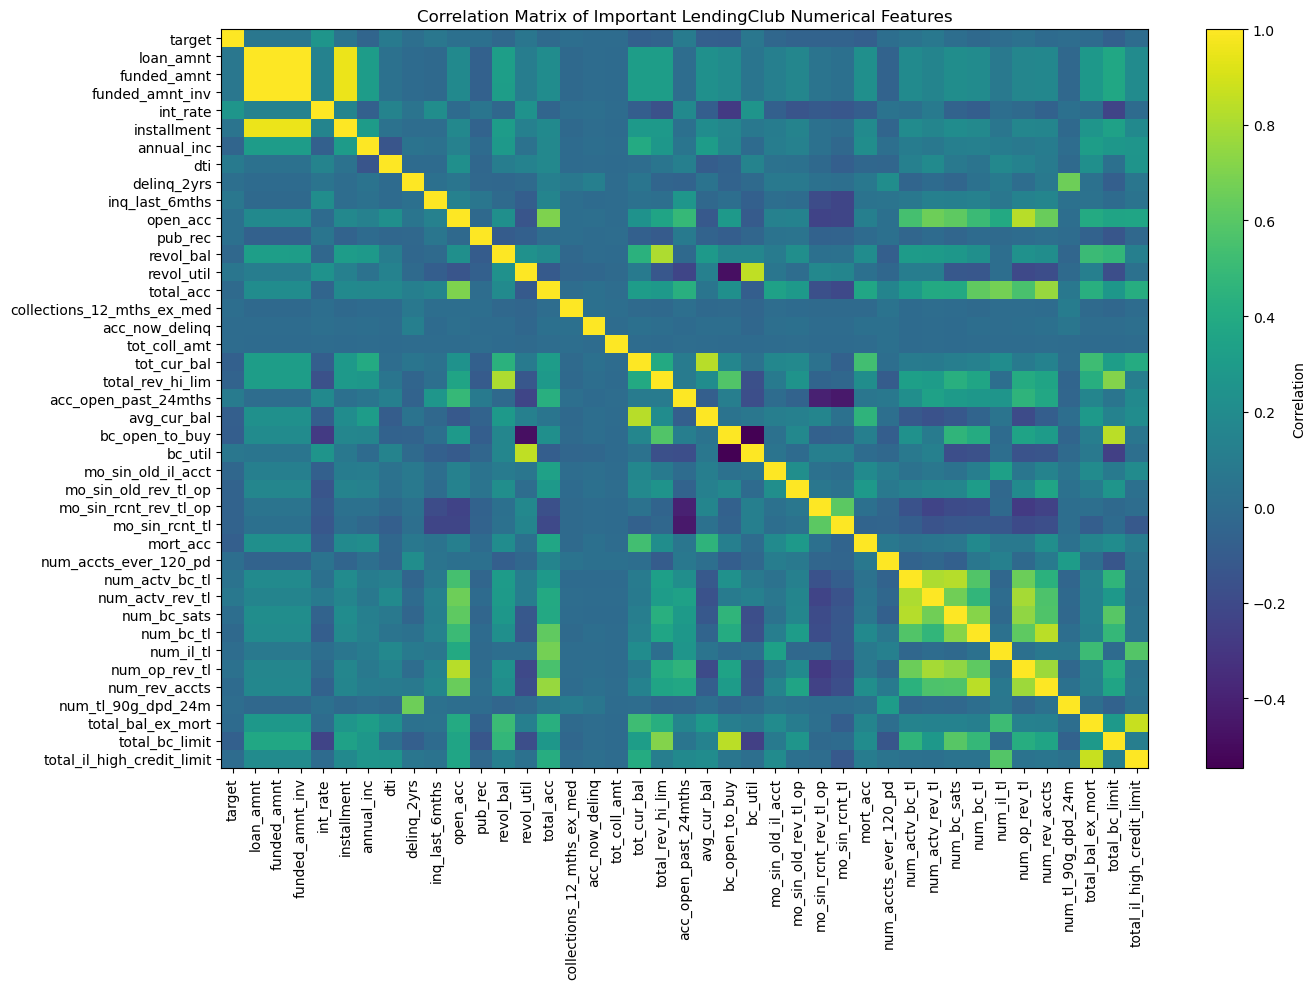

In [23]:
plt.figure(figsize=(14, 10))

plt.imshow(corr_matrix, aspect="auto")
plt.colorbar(label="Correlation")

plt.xticks(
    ticks=range(len(corr_matrix.columns)),
    labels=corr_matrix.columns,
    rotation=90
)

plt.yticks(
    ticks=range(len(corr_matrix.index)),
    labels=corr_matrix.index
)

plt.title("Correlation Matrix of Important LendingClub Numerical Features")

plt.tight_layout()
plt.show()